# Comparaison de 36 stratégies de value betting

**Décision : aucune candidate retenue, rentabilité future non estimable.**

Analyse rétrospective figée du 14 octobre 2026, sur les matchs du 7 au 13 octobre.
Les agrégats avaient déjà été consultés : cette séparation chronologique ne constitue pas un test indépendant.
Voir `docs/protocole-comparaison.md` pour les règles fixées avant le calcul ; `docs/comparaison-strategies.md` pour les conclusions.

Ce notebook lit le relevé JSON versionné, sans réseau. Pour recalculer depuis les paris bruts, utiliser `scripts/comparer_strategies.py` avec le commit de données indiqué ci-dessous.
Dépendances de lecture : pandas, matplotlib, nbformat, nbclient, ipykernel.

In [1]:
from pathlib import Path
import json, sys
import pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from IPython.display import display, SVG
root = Path.cwd()
if not (root / "cotes").exists():
    root = root.parent
sys.path.insert(0, str(root))
from cotes.laboratoire import REGLES, classer
r = json.loads((root / "docs/comparaison-strategies.json").read_text())
assert len(r["resultats"]) == len(REGLES) == 36
assert classer(r["resultats"]) == r["decision"]
display(pd.Series(r["source"], name="Source"))
print("Relevé connu au :", r["releve"])
print("Décision :", r["decision"])

Relevé connu au : 2026-10-14T10:09:28Z
Décision : {'finalistes': [], 'candidate': None, 'test_reussi': False, 'rentabilite_demontree': False}


depot                                         Matttgic/cotes-value
branche                                                    donnees
commit                    56bed648894f383f04fb42f677ee9223d29c2abe
sha256_paris     5d1a044eb1a5fbaf7261e2a149eaef2937731af42a7cbd...
dernier_cycle                            2026-10-14T10:06:11+00:00
Name: Source, dtype: object

## Audit

9 307 lignes ne correspondent pas à autant d'événements indépendants. Le témoin Pinnacle brut est exclu.
Les motifs d'exclusion ci-dessous sont évalués avant sélection par plage de cotes, edge, délai et dédoublonnage.
L'absence de conflit détecté n'est pas une preuve d'exécutabilité de la cote ou d'exactitude de chaque score.

In [2]:
a = r["audit"]
assert not any(a[k] for k in ("ids_dupliques", "gains_incoherents", "dates_reglement_invalides", "conflits_reglement_meme_selection"))
display(pd.Series({k: a[k] for k in ("lignes", "temoin_brut", "vraies_references", "ids_dupliques")}, name="Effectif"))
display(pd.Series(a["par_reference"], name="Lignes par référence"))
display(pd.Series(a["qualite_3_references"], name="Qualité des 3 références"))

lignes               9307
temoin_brut          7881
vraies_references    1426
ids_dupliques           0
Name: Effectif, dtype: int64

Kalshi        122
Pinnacle      877
Polymarket    203
Betfair        93
Consensus     131
Name: Lignes par référence, dtype: int64

preuve_insuffisante    374
admissible             404
marche_ou_periode      371
dates_ou_fraicheur       6
unite_ambigue           18
Name: Qualité des 3 références, dtype: int64

## Tableau des 36 règles

Construction : 7–10 octobre ; validation : 11–12 octobre ; test final : 13 octobre (heure de Paris).
ROI = gain net / mises réglées ; chaque pari est simulé à 10 €. Les paris en attente ne sont pas imputés comme pertes.
La sélection initiale exige 20 réglés, ROI > 0, CLV > 0 et couverture CLV ≥ 50 % en construction.
Les cellules vides sont des valeurs non estimables, jamais des zéros.

In [3]:
rows=[]
for x in r["resultats"]:
    row={"Règle":x["regle"]["id"]}
    for p in ("construction", "validation", "test"):
        for k in ("regles", "attente", "roi", "clv"):
            row[f"{p} / {k}"]=x[p][k]
    rows.append(row)
df=pd.DataFrame(rows).set_index("Règle")
with pd.option_context("display.max_rows", 40, "display.max_columns", 20):
    display(df.round(2))
volumes=[x for x in r["resultats"] if x["construction"]["regles"]>=20]
assert len(volumes)==4 and all(x["construction"]["roi"]<0 for x in volumes)
print("Variantes avec au moins 20 réglés :",len(volumes),"; aucune avec un ROI positif.")

Variantes avec au moins 20 réglés : 4 ; aucune avec un ROI positif.


,construction / regles,construction / attente,construction / roi,construction / clv,validation / regles,validation / attente,validation / roi,validation / clv,test / regles,test / attente,test / roi,test / clv
Règle,,,,,,,,,,,,
PIN-1.3-2-e2-h12,11,0,3.00,1.18,9,0,-31.56,1.05,5,3,-2.00,1.51
PIN-1.3-2-e2-h36,28,2,-1.04,1.19,16,0,-8.62,-0.84,9,3,30.78,3.07
PIN-1.3-2-e5-h12,1,0,-100.00,6.85,1,0,-100.00,7.17,0,1,NaN,NaN
PIN-1.3-2-e5-h36,4,2,-7.75,8.53,1,0,-100.00,7.17,2,1,71.50,8.18
PIN-1.5-3-e2-h12,15,2,-29.47,-1.10,13,0,-18.77,-0.89,5,2,-29.00,0.86
PIN-1.5-3-e2-h36,36,4,-24.47,0.49,20,1,-19.10,-1.62,12,2,37.00,4.63
PIN-1.5-3-e5-h12,7,1,-70.00,1.16,4,0,-100.00,-3.65,0,1,NaN,NaN
PIN-1.5-3-e5-h36,10,3,-42.10,-2.88,5,1,-100.00,-3.65,5,1,68.00,5.11
PIN-2-5-e2-h12,20,3,-61.50,1.14,9,0,-4.44,-3.53,3,2,10.00,5.02


## Volume et résultat de construction

Le quadrant à droite de 20 réglés et au-dessus de 0 % est vide. La couleur distingue la référence.
Chaque point représente une règle ; certains se superposent. Les règles sans pari réglé sont exclues du graphique.
Ce graphique descriptif ne mesure pas l'incertitude ni l'indépendance des règles.

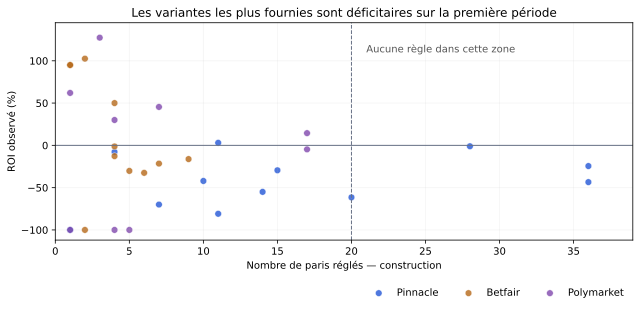

In [4]:
plt.rcParams.update({"svg.fonttype":"none", "font.size":10})
fig, ax = plt.subplots(figsize=(9,4.5))
colors={"Pinnacle":"#2457d6", "Betfair":"#b56818", "Polymarket":"#8047ad"}
for ref, color in colors.items():
    xs=[x for x in r["resultats"] if x["regle"]["reference"]==ref and x["construction"]["regles"]]
    ax.scatter([x["construction"]["regles"] for x in xs], [x["construction"]["roi"] for x in xs],
               label=ref, color=color, s=45, alpha=.8, edgecolor="white", linewidth=.5)
ax.axvline(20,color="#667085",ls="--",lw=1)
ax.axhline(0,color="#667085",lw=1)
ax.text(21,110,"Aucune règle dans cette zone",fontsize=10,color="#555")
ax.set(xlim=(0,39),ylim=(-112,145),xlabel="Nombre de paris réglés — construction",ylabel="ROI observé (%)",
       title="Les variantes les plus fournies sont déficitaires sur la première période")
ax.legend(loc="upper right",bbox_to_anchor=(1,-.18),ncol=3,frameon=False)
ax.grid(alpha=.13)
fig.tight_layout()
fig.savefig(root/"docs/comparaison-construction.svg",bbox_inches="tight")
fig.savefig("/tmp/comparaison-construction.png",dpi=140,bbox_inches="tight")
display(SVG((root/"docs/comparaison-construction.svg").read_text()))
plt.close(fig)

## Sensibilité : exemple positif mais non retenu

Polymarket, cotes 1,50–3,00, edge 2–12 %, délai 36 h. Cet exemple est choisi **après lecture**, pour expliquer les limites ; il n'est pas une candidate promue.
Les IC à 95 % sont conditionnels à la règle et non corrigés des 36 essais. Le bootstrap par match ignore la corrélation entre rencontres d'une journée et devient trompeur sur de très petits échantillons.

In [5]:
x=next(x for x in r["resultats"] if x["regle"]["id"]=="POL-1.5-3-e2-h36")
keys=["regles","attente","gain","roi","ic95","clv","clv_n","couverture_clv","gain_sans_meilleur","roi_cote_moins_1pct","drawdown"]
display(pd.DataFrame({p:{k:x[p][k] for k in keys} for p in ("construction","validation","test")}))
display(pd.DataFrame({p:x[p]["profit_journalier"] for p in ("construction","validation","test")}))
print("La période de validation ne passe ni le minimum de 10 réglés ni la CLV positive.")
print("Test final sans le meilleur gain :", x["test"]["gain_sans_meilleur"],"€.")

La période de validation ne passe ni le minimum de 10 réglés ni la CLV positive.
Test final sans le meilleur gain : -3.3 €.


,construction,validation,test
regles,17,6,7
attente,0,1,0
gain,24.6,27.8,16.2
roi,14.47,46.33,23.14
ic95,"[-38.88, 66.47]","[-44.5, 136.0]","[-57.86, 107.43]"
clv,6.01,-1.58,0.19
clv_n,14,6,7
couverture_clv,82.4,100.0,100.0
gain_sans_meilleur,5.1,9.8,-3.3
roi_cote_moins_1pct,13.33,44.87,21.91


,construction,validation,test
2026-10-07,19.5,NaN,NaN
2026-10-08,6.2,NaN,NaN
2026-10-09,-8.1,NaN,NaN
2026-10-10,7.0,NaN,NaN
2026-10-11,NaN,25.0,NaN
2026-10-12,NaN,2.8,NaN
2026-10-13,NaN,NaN,16.2


## Comparateurs et décision

Claude et ChatGPT V1 sont rejoués en remontant leur date de départ au 7 octobre. Ces calculs sont distincts de leurs bilans officiels.
Claude peut engager plusieurs paris par match ; son intervalle par pari est volontairement absent pour ne pas ignorer cette corrélation.
Les règles de comparaison utilisent une seule mise par événement. Les mises des 36 stratégies ne doivent pas être additionnées.

In [6]:
comparateurs=[]
for nom, periodes in r["comparateurs"].items():
    for periode,s in periodes.items():
        comparateurs.append({"Rejeu":nom,"Période":periode,**{k:s[k] for k in ("regles","attente","gain","roi","clv","gain_sans_meilleur")}})
display(pd.DataFrame(comparateurs).set_index(["Rejeu","Période"]))
assert r["decision"]["candidate"] is None
print("Aucune règle retenue. Ne pas convertir les gains passés en estimation de revenu futur.")

Aucune règle retenue. Ne pas convertir les gains passés en estimation de revenu futur.


regles  attente  ...   clv  gain_sans_meilleur
Rejeu              Période                        ...                          
ChatGPT v1 (rejeu) construction       3        1  ... -1.54               -30.0
                   validation         7        0  ... -6.19                -8.4
                   test               2        1  ... -4.62               -10.0
Claude (rejeu)     construction      74       11  ...  5.55                27.2
                   validation        58        3  ...  2.54                74.2
                   test              15        1  ... -1.52                -2.3

[6 rows x 6 columns]

## Suite opérationnelle

Les 36 règles sont suivies séparément à partir du **14 octobre 2026 à 14 h (Paris)**, uniquement pour les nouvelles détections.
Bilan → Laboratoire expose leurs résultats futurs et leurs sélections. Aucun changement automatique des seuils selon les profits récents.
Une éventuelle promotion nécessitera un protocole prospectif et une date de décision fixés avant de réexaminer ce suivi.